In [ ]:
from dotenv import load_dotenv
from langchain_groq import ChatGroq
import os
from typing import TypedDict,Literal,NotRequired
load_dotenv()
from pydantic import BaseModel,Field
from tavily import TavilyClient
from langchain_core.messages import SystemMessage,HumanMessage
from langchain_mcp_adapters.client import MultiServerMCPClient
from langgraph.prebuilt import create_react_agent
from langgraph.graph import StateGraph,START,END
import sys
try:
  sys.stderr.fileno()
except Exception:
  _errlog = open(os.devnull, "w")
  sys.stderr.fileno = _errlog.fileno

In [ ]:
from langchain_openai import ChatOpenAI

boss_model = ChatOpenAI(model="gpt-6-luna")

In [ ]:
prompt_model=ChatGroq(model="openai/gpt-oss-20b",api_key=os.getenv("groq2"))
class Detail_prompt(BaseModel):
  Detail_prompt_template: str

class Planning(BaseModel):
  scene_type: str = Field(
      default="object",
      description="One of: object, assembly, interior, environment, organic, abstract"
  )
  style: str = Field(
      default="As described in the technical specification",
      description="Visual style (e.g., photorealistic, stylized, low-poly)"
  )
  main_goal: str = Field(
      description="Core objective of the Blender scene or asset"
  )
  requires_research: bool = Field(default=False)
  steps: list[str] = Field(
      description="Ordered step-by-step Blender `bpy` construction plan."
  )

class RouterDecision(BaseModel):
  needs_internetsearch: bool
  mode: Literal["closed_book", "hybrid", "open_book"]
  queries: list[str] = Field(default_factory=list)

class MainState(TypedDict):
  user_prompt: str
  detail_prompt: str
  mode: str
  needs_research: bool
  queries: NotRequired[list[str]]
  research_state: NotRequired[str]
  plan: str
  execution_result: NotRequired[str]

In [4]:
def structured_invoke(schema, messages, models, attempts_per_model=2, validate=None):
  """Call structured output, retrying and falling back to the next model on bad/empty JSON."""
  last_error = None
  for model in models:
    structured = model.with_structured_output(schema, method="json_schema")
    for _ in range(attempts_per_model):
      try:
        result = structured.invoke(messages)
        if validate is None or validate(result):
          return result
        last_error = ValueError("structured output failed validation")
      except Exception as exc:
        last_error = exc
  raise RuntimeError(f"Structured output failed on all models: {last_error}")


In [5]:
BLENDER_SYSTEM_PROMPT = """You are an expert 3D Technical Artist and Blender Python (bpy) Specialist.
Your job is to expand a short user prompt into a detailed, unambiguous technical specification for ANY kind of 3D scene or asset in Blender.

First classify the request as one Scene Type: object, assembly, interior, environment, organic, or abstract.

Then expand it across these dimensions:
1. **Geometry & Modeling**: primary shapes, real-world proportions and scale (meters), modifiers (Bevel, Subdivision Surface, Mirror, Array, Solidify, Boolean, Displace), topology needs. For multi-part objects give each part's start/end coordinates so every part touches the previous one.
2. **Materials & Shaders**: Principled BSDF values and procedural textures that match EVERY adjective in the request (wood, metal, glass, fabric, concrete, glossy, emissive...).
3. **Scene & Composition**: object placement, hierarchy/collections, ground or room shell, and camera (lens, angle, distance scaled to the subject's size; eye-height camera inside interiors).
4. **Lighting & World**: choose the lighting style from the request's mood (warm/cozy, sunny daylight, clean studio, dramatic night), with color temperature and light placement. Lights that belong to an object (lamp, lantern, neon) go inside or at that object.
5. **Technical & Research Needs**: note whether real-world dimensions, brand designs or external references are required so downstream nodes can decide if web search is needed.

Rules:
- Use a Z-up metric coordinate system with objects standing on the ground at z = 0.
- Preserve every adjective and constraint from the user's request; add nothing decorative that was not asked for.
- Minimalist means few clean primitives with correct proportions. Organic or character requests are specified as clean stylized forms built from primitives, Subdivision and Mirror. Animation is specified only if the user asked for it.
- Keep the specification under 500 words, clear, structured and ready for a planning agent and a bpy code generator.
- Do not write Python code yet; output only the detailed technical description."""

def detail_prompt_temp(state:MainState)->dict:
    user_prompt=state['user_prompt']
    detail_prompt=structured_invoke(
        Detail_prompt,
        [SystemMessage(content=BLENDER_SYSTEM_PROMPT),HumanMessage(content=user_prompt)],
        [boss_model],
        validate=lambda r: len(r.Detail_prompt_template.strip()) > 50,
    )
    return {'detail_prompt':detail_prompt.Detail_prompt_template}

In [6]:
ROUTER_SYSTEM_PROMPT = """You are a routing module for a Blender scene planner.
Read the technical specification and decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_internetsearch=false): generic objects that need no outside facts.
- hybrid (needs_internetsearch=true): mostly generic, but real-world dimensions or reference details would help.
- open_book (needs_internetsearch=true): depends on specific real-world products, brands or recent information.

If needs_internetsearch is true, return 1-3 specific search queries; otherwise return an empty list.
Return only the JSON object matching the schema."""

def router_node(state: MainState) -> dict:
  try:
    decision = structured_invoke(
        RouterDecision,
        [SystemMessage(content=ROUTER_SYSTEM_PROMPT),HumanMessage(content=state["detail_prompt"])],
        [prompt_model, boss_model],
    )
  except RuntimeError:
    decision = RouterDecision(needs_internetsearch=False, mode="closed_book", queries=[])
  return {
      "needs_research": decision.needs_internetsearch,
      "mode": decision.mode,
      "queries": decision.queries,
  }
def route_research(state: MainState) -> str:
  if state.get("needs_research") and state.get("queries"):
    return "web_search"
  return "planning_node"

In [7]:
client = TavilyClient(
    api_key=os.environ["TAVILY_API_KEY"]
)
def web_search(state: MainState) -> dict:
  queries = state.get("queries", [])
  all_results = []
  for q in queries:
    response = client.search(query=q)
    for r in response.get("results", []):
      all_results.append(
          f"Query: {q}\nSource: {r['url']}\nContent: {r['content']}"
      )
  return {"research_state": "\n\n---\n\n".join(all_results)}

In [ ]:
PLANNING_SYSTEM_PROMPT = """You are a Lead Blender Technical Director.
Create a precise, ordered execution plan for building ANY 3D scene in Blender using Python (`bpy`).

Use the provided Technical Specification and any Web Research Context (if available) to produce:
1. **Scene Type**: one of object, assembly, interior, environment, organic, abstract.
2. **Style**: the target visual style.
3. **Main Goal**: a concise summary of what is being built.
4. **Steps**: a logical, sequential build order of 8-14 steps:
   - Step 1: scene reset, metric units, collection organization.
   - Middle steps: base geometry with exact dimensions and coordinates, modifiers and refinements, then materials that match every adjective in the request.
   - Then lighting and world chosen from the request's mood, then the camera (distance scaled to the subject's size, eye height for interiors).
   - Final step: Verification (everything in frame, lights present, materials assigned, connected parts touching, any enclosed light inside its enclosure).

Rules:
- Always return all four fields: scene_type, style, main_goal and steps.
- Every geometry step gives numeric dimensions in meters; connected parts start exactly where the previous part ends (no gaps).
- Incorporate real-world dimensions or facts from the Web Research Context if provided.
- Keep each step concrete and ready to be translated directly into `bpy` code. Do not write Python code yet."""
def planning_node(state: MainState) -> dict:
    detail_prompt = state["detail_prompt"]
    research_context = state.get("research_state", "")
    user_content = f"### Technical Specification:\n{detail_prompt}"
    if research_context:
        user_content += (
            f"\n\n### Web Research Context:\n{research_context}"
        )
    plan_obj = structured_invoke(
        Planning,
        [SystemMessage(content=PLANNING_SYSTEM_PROMPT),HumanMessage(content=user_content)],
        [boss_model, prompt_model],
        validate=lambda r: len(r.steps) >= 3,
    )
    formatted_steps = "\n".join(
        [f"{i + 1}. {step}" for i, step in enumerate(plan_obj.steps)]
    )
    formatted_plan = (
        f"Scene Type: {plan_obj.scene_type}\n"
        f"Style: {plan_obj.style}\n"
        f"Main Goal: {plan_obj.main_goal}\n"
        f"Steps:\n{formatted_steps}"
    )
    return {"plan": formatted_plan}

In [ ]:
mcp_client = MultiServerMCPClient({
    "blender": {
        "transport": "stdio",
        "command": "uvx",
        "args": ["mcp-for-blender"],
        "env": {"BLENDER_PORT": "8000"},
    }
})
async def load_blender_tools():
  return await mcp_client.get_tools()


In [10]:

BLENDER_AGENT_PROMPT = """You are a senior Blender 4.x technical artist executing a build plan through MCP tools.
You write correct, compact bpy code and you verify the result numerically before finishing.
You can build ANY kind of scene (objects, assemblies, interiors, environments, stylized characters, text and abstract art). Follow the Scene Type given in the plan.

WORKFLOW
1. Never assume the scene state. Your first code call must reset the scene (delete every object and orphan data) so no default Cube, Light or Camera remains.
2. Work in stages, one code call per stage, at most 6 calls: (A) reset + geometry, (B) more geometry if the scene is large, (C) materials, (D) lighting + world, (E) camera + render settings, (F) verification. Scene data persists between calls, Python variables do not: re-fetch objects by name and paste the helpers you need.
3. If a call returns a traceback, fix only its cause and rerun that stage. Never repeat a successful stage.
4. Finish only after verification prints PASS. Then reply with a short summary (objects, materials, lights, camera, anything approximated).

GLOBAL RULES
- Units are metres, Z is up, the ground is z = 0, and objects stand on the ground.
- Use real-world proportions for the thing being built. Compute positions from earlier parts' coordinates so connected parts touch. Never place parts by eye.
- Honour every adjective in the ORIGINAL REQUEST (material, colour, mood, time of day, style). Pick materials, lighting and camera from that intent, not from a template.
- Name every object, put everything (camera and lights too) in a collection called "Scene_Asset", add bevels and smooth shading to hard-surface parts, use a fixed random seed for any randomness.
- Use only primitives, modifiers (Bevel, Subdivision, Mirror, Array, Solidify, Boolean, Displace, Skin), curves, text objects, metaballs and procedural nodes. Do not rely on downloaded assets or image files.
- Be honest about limits: organic or character requests are built as clean stylized forms (spheres, capsules, Subdivision, Mirror), not photoreal sculpts. Mention this in the summary.
- Render engine CYCLES with denoising on. Do not start a render unless the request asks for one.

SCENE TYPE PLAYBOOK
- object / assembly: floor sized 3x the largest dimension; assemblies are chains (each part starts where the previous ends); verify with gap().
- interior: build the room shell from boxes (walls 0.1-0.2 m thick, floor, ceiling) with window or door openings (Boolean or separate wall pieces), then furniture with real sizes (door 2.0 m, table 0.75 m, chair seat 0.45 m). Camera inside the room at eye height 1.4-1.6 m, lens 24-28 mm, aimed at the room centre. Prefer 'warm_interior' or 'daylight' lighting.
- environment: terrain = subdivided plane + Displace modifier with a Noise texture; scatter repeated items (trees, rocks, buildings) with a seeded random loop using linked duplicates; sun + sky; wide camera (30-35 mm) from an elevated angle with frame_camera.
- organic: build from Subdivision-surface spheres/capsules joined logically (body, head, limbs) with Mirror modifiers; smooth shading; pose simply.
- abstract / text: use FONT curves with extrude and bevel for text, Array/Wave/Displace for patterns, emissive or glossy materials.
- animation (only if requested): set scene.frame_start/frame_end/fps and use keyframe_insert on location/rotation/scale.

HELPERS (reuse these patterns exactly)
```python
import bpy, math, random
from mathutils import Vector

def reset_scene():
    if bpy.context.object and bpy.context.object.mode != 'OBJECT':
        bpy.ops.object.mode_set(mode='OBJECT')
    bpy.ops.object.select_all(action='SELECT')
    bpy.ops.object.delete()
    for store in (bpy.data.meshes, bpy.data.curves, bpy.data.materials, bpy.data.lights, bpy.data.cameras, bpy.data.collections):
        for blk in list(store):
            store.remove(blk)
    coll = bpy.data.collections.new("Scene_Asset")
    bpy.context.scene.collection.children.link(coll)
    bpy.context.scene.render.engine = 'CYCLES'
    bpy.context.scene.cycles.use_denoising = True
    return coll

def to_coll(obj, coll):
    for c in list(obj.users_collection):
        c.objects.unlink(obj)
    coll.objects.link(obj)

def finish(obj, coll, bevel=0.002):
    for p in obj.data.polygons:
        p.use_smooth = True
    if bevel > 0:
        m = obj.modifiers.new("Bevel", 'BEVEL')
        m.width = bevel
        m.segments = 3
    to_coll(obj, coll)

def box(centre, size, name, coll, bevel=0.002):
    bpy.ops.mesh.primitive_cube_add(size=1.0, location=centre)
    o = bpy.context.active_object
    o.name = name
    o.scale = Vector(size)
    bpy.ops.object.transform_apply(scale=True)
    finish(o, coll, bevel)
    return o

def cylinder_between(p1, p2, radius, name, coll, verts=48):
    p1, p2 = Vector(p1), Vector(p2)
    d = p2 - p1
    bpy.ops.mesh.primitive_cylinder_add(vertices=verts, radius=radius, depth=d.length, location=(p1 + p2) / 2)
    o = bpy.context.active_object
    o.name = name
    o.rotation_mode = 'QUATERNION'
    o.rotation_quaternion = d.to_track_quat('Z', 'Y')
    finish(o, coll)
    return o

def sphere_at(p, radius, name, coll, bevel=0.0):
    bpy.ops.mesh.primitive_uv_sphere_add(radius=radius, segments=48, ring_count=24, location=p)
    o = bpy.context.active_object
    o.name = name
    finish(o, coll, bevel)
    return o

def open_cone(bottom_r, top_r, height, centre, name, coll, tilt_x_deg=0.0):
    # wide end (radius1) is at local -Z, so with no tilt the cone opens downward
    bpy.ops.mesh.primitive_cone_add(vertices=64, radius1=bottom_r, radius2=top_r, depth=height, end_fill_type='NOTHING', location=centre)
    o = bpy.context.active_object
    o.name = name
    o.rotation_euler[0] = math.radians(tilt_x_deg)
    s = o.modifiers.new("Solidify", 'SOLIDIFY')
    s.thickness = 0.003
    for p in o.data.polygons:
        p.use_smooth = True
    to_coll(o, coll)
    return o

def add_floor(size, coll, color=(0.55, 0.55, 0.55, 1)):
    bpy.ops.mesh.primitive_plane_add(size=size, location=(0, 0, 0))
    o = bpy.context.active_object
    o.name = "Floor"
    to_coll(o, coll)
    o.data.materials.append(pbr("Floor_Mat", color, 0.0, 0.8))
    return o

def pbr(name, color, metallic=0.0, roughness=0.5, emission=None, emission_strength=5.0, transmission=0.0, ior=1.45):
    m = bpy.data.materials.new(name)
    m.use_nodes = True
    b = m.node_tree.nodes["Principled BSDF"]
    b.inputs['Base Color'].default_value = color
    b.inputs['Metallic'].default_value = metallic
    b.inputs['Roughness'].default_value = roughness
    b.inputs['IOR'].default_value = ior
    for key in ('Transmission Weight', 'Transmission'):
        if key in b.inputs:
            b.inputs[key].default_value = transmission
            break
    if emission is not None:
        b.inputs['Emission Color'].default_value = emission
        b.inputs['Emission Strength'].default_value = emission_strength
    return m

def wood_material(name="Wood"):
    m = bpy.data.materials.new(name)
    m.use_nodes = True
    nt = m.node_tree
    bsdf = nt.nodes["Principled BSDF"]
    coord = nt.nodes.new("ShaderNodeTexCoord")
    wave = nt.nodes.new("ShaderNodeTexWave")
    wave.bands_direction = 'X'
    wave.inputs['Scale'].default_value = 5.0
    wave.inputs['Distortion'].default_value = 8.0
    wave.inputs['Detail'].default_value = 3.0
    ramp = nt.nodes.new("ShaderNodeValToRGB")
    ramp.color_ramp.elements[0].color = (0.30, 0.16, 0.07, 1)
    ramp.color_ramp.elements[1].color = (0.62, 0.38, 0.18, 1)
    nt.links.new(coord.outputs['Object'], wave.inputs['Vector'])
    nt.links.new(wave.outputs['Color'], ramp.inputs['Fac'])
    nt.links.new(ramp.outputs['Color'], bsdf.inputs['Base Color'])
    bsdf.inputs['Roughness'].default_value = 0.45
    return m

def set_world(color, strength):
    w = bpy.context.scene.world or bpy.data.worlds.new("World")
    bpy.context.scene.world = w
    w.use_nodes = True
    bg = w.node_tree.nodes["Background"]
    bg.inputs['Color'].default_value = (*color, 1)
    bg.inputs['Strength'].default_value = strength

def add_light(name, kind, location, coll, watts, color=(1, 1, 1), size=0.1, rotation_deg=None):
    ld = bpy.data.lights.new(name, kind)
    ld.energy = watts
    ld.color = color
    if kind == 'AREA':
        ld.size = size
    elif kind in ('POINT', 'SPOT'):
        ld.shadow_soft_size = size
    lo = bpy.data.objects.new(name, ld)
    lo.location = location
    if rotation_deg:
        lo.rotation_euler = [math.radians(a) for a in rotation_deg]
    coll.objects.link(lo)
    return lo

def aim(obj, target_obj):
    c = obj.constraints.new('TRACK_TO')
    c.target = target_obj
    c.track_axis = 'TRACK_NEGATIVE_Z'
    c.up_axis = 'UP_Y'

def subject_bounds(coll):
    subs = [o for o in coll.objects if o.type in {'MESH', 'CURVE', 'FONT'} and o.name != "Floor"]
    pts = [o.matrix_world @ Vector(c) for o in subs for c in o.bound_box]
    lo = Vector(map(min, zip(*pts)))
    hi = Vector(map(max, zip(*pts)))
    return subs, lo, hi

def lighting_rig(kind, coll):
    # kind: 'studio' | 'daylight' | 'warm_interior' | 'dramatic'
    subs, lo, hi = subject_bounds(coll)
    c = (lo + hi) / 2
    s = max((hi - lo).length, 0.3)
    d = 1.6 * s
    tgt = bpy.data.objects.new("Light_Target", None)
    tgt.location = c
    coll.objects.link(tgt)
    if kind == 'studio':
        set_world((0.03, 0.03, 0.035), 1.0)
        for n, off, k, col in (("Key", (1, -1, 1), 1.0, (1, 0.97, 0.92)), ("Fill", (-1.3, -0.6, 0.5), 0.35, (0.9, 0.95, 1)), ("Rim", (0, 1.3, 1), 0.6, (1, 1, 1))):
            L = add_light(n, 'AREA', c + Vector(off) * d, coll, 120 * d * d * k, col, size=d * 0.6)
            aim(L, tgt)
    elif kind == 'daylight':
        sun = add_light("Sun", 'SUN', (0, 0, 10), coll, 3.0, (1, 0.96, 0.88), size=0.01, rotation_deg=(50, 0, 30))
        sun.data.energy = 3.0
        try:
            w = bpy.context.scene.world or bpy.data.worlds.new("World")
            bpy.context.scene.world = w
            w.use_nodes = True
            sky = w.node_tree.nodes.new("ShaderNodeTexSky")
            sky.sky_type = 'NISHITA'
            w.node_tree.links.new(sky.outputs['Color'], w.node_tree.nodes["Background"].inputs['Color'])
        except Exception:
            set_world((0.5, 0.7, 1.0), 1.0)
    elif kind == 'warm_interior':
        set_world((0.02, 0.015, 0.01), 0.3)
        add_light("Warm_Main", 'POINT', c + Vector((0, 0, 0.8 * s)), coll, 150 * d, (1.0, 0.58, 0.29), size=0.05)
    else:
        set_world((0.005, 0.005, 0.008), 0.2)
        L = add_light("Spot", 'SPOT', c + Vector((1, -1, 1.5)) * d, coll, 300 * d * d, (1, 0.9, 0.8), size=0.05)
        aim(L, tgt)
        R = add_light("Rim", 'AREA', c + Vector((-1, 1.2, 0.8)) * d, coll, 80 * d * d, (0.6, 0.7, 1), size=d * 0.5)
        aim(R, tgt)

def frame_camera(coll, lens=50.0, elevation_deg=20.0, azimuth_deg=35.0, margin=1.35):
    subs, lo, hi = subject_bounds(coll)
    c = (lo + hi) / 2
    radius = (hi - lo).length / 2
    fov = 2 * math.atan((36.0 * 9 / 16) / (2 * lens))
    dist = margin * radius / math.sin(fov / 2)
    el, az = math.radians(elevation_deg), math.radians(azimuth_deg)
    loc = c + Vector((math.sin(az) * math.cos(el), -math.cos(az) * math.cos(el), math.sin(el))) * dist
    tgt = bpy.data.objects.new("Camera_Target", None)
    tgt.location = c
    coll.objects.link(tgt)
    cd = bpy.data.cameras.new("Camera")
    cd.lens = lens
    cd.clip_end = max(100.0, dist * 10)
    co = bpy.data.objects.new("Camera", cd)
    co.location = loc
    coll.objects.link(co)
    aim(co, tgt)
    bpy.context.scene.camera = co
    return co
```
Lighting choice: warm / cozy / evening -> 'warm_interior' (plus any in-object light the plan specifies, placed inside its shade or enclosure); sunny / outdoor / daytime -> 'daylight'; product / clean / neutral -> 'studio'; moody / night / dramatic -> 'dramatic'. If the plan places a light inside an object (lamp, lantern, neon), keep that light and add only a dim world.
Camera choice: object/assembly/environment -> frame_camera (adjust elevation or lens to the request); interior -> manual eye-height camera inside the room with aim().
Assign materials with obj.data.materials.append(mat); use an emissive pbr() material for visible bulbs, screens and neon.

VERIFICATION (final stage; print PASS or FAIL with reasons, fix and rerun until PASS)
```python
import bpy
from mathutils import Vector
from bpy_extras.object_utils import world_to_camera_view

def world_bbox(o):
    pts = [o.matrix_world @ Vector(c) for c in o.bound_box]
    return Vector(map(min, zip(*pts))), Vector(map(max, zip(*pts)))

def gap(a, b):
    amin, amax = world_bbox(a)
    bmin, bmax = world_bbox(b)
    return max(0.0, *(max(amin[i] - bmax[i], bmin[i] - amax[i]) for i in range(3)))
```
Always check: (1) no leftover default 'Cube'; exactly one scene camera that is set as scene.camera; (2) at least one light with energy > 0; (3) every mesh has a material; (4) for non-interior scenes, every corner of every subject bbox projects inside 0..1 with world_to_camera_view; for interiors, the camera lies inside the room bounds and sees the room centre. Check only when relevant: (5) for object/assembly scenes, gap() between each consecutive pair in the plan's chain is <= 0.002 m; (6) if a light is meant to sit inside an enclosure, its location lies inside that object's world bbox.
"""


async def blender_mcp_node(state: MainState) -> dict:
  tools = await mcp_client.get_tools()
  blender_agent = create_react_agent(boss_model, tools)

  result = await blender_agent.ainvoke({
      "messages": [
          SystemMessage(content=BLENDER_AGENT_PROMPT),
          HumanMessage(
              content=f"ORIGINAL REQUEST: {state['user_prompt']}\n\nExecute this Blender plan now:\n\n{state['plan']}"
          ),
      ]
  }, config={"recursion_limit": 100})
  final_message = result["messages"][-1].content
  return {"execution_result": final_message}

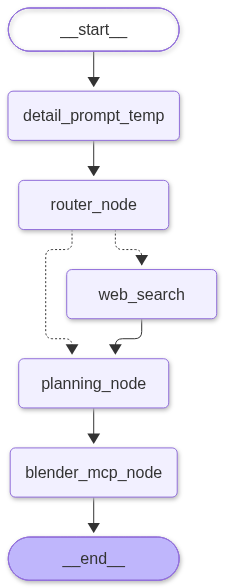

In [11]:
graph=StateGraph(MainState)
graph.add_node('detail_prompt_temp',detail_prompt_temp)
graph.add_node('router_node',router_node)
graph.add_node('web_search',web_search)
graph.add_node('planning_node',planning_node)
graph.add_node('blender_mcp_node',blender_mcp_node)
graph.add_edge(START,'detail_prompt_temp')
graph.add_edge('detail_prompt_temp','router_node')
graph.add_conditional_edges("router_node",route_research,{"web_search": "web_search", "planning_node": "planning_node"})
graph.add_edge('web_search','planning_node')
graph.add_edge('planning_node','blender_mcp_node')
graph.add_edge('blender_mcp_node',END)
agent=graph.compile()
agent

In [12]:
import asyncio
from concurrent.futures import ThreadPoolExecutor


def run_in_proactor_loop(coro):
  def runner():
    asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())
    return asyncio.run(coro)

  with ThreadPoolExecutor(max_workers=1) as executor:
    return executor.submit(runner).result()

initial_state = {
    "user_prompt": "Create a stylized low-poly 1994 Toyota Supra MK4 (JZA80) coupe assembly in Blender standing at z=0 with real-world metric proportions. Separate into collections: Body, Wheels, Glass, Lights, and Spoiler. Use Mirror along X-axis and Subdivision Surface (level 2) with panel crease weights for the long front hood, sloped fastback roofline, lower front bumper air intakes, and iconic curved hoop rear spoiler. Add four 5-spoke metallic alloy wheels with brake calipers inside the wheel arches. Assign glossy red clearcoat Principled BSDF paint to the body, dark tinted glass shader to windows, and emissive white/red shaders for the headlights and quad circular taillights. Place on a clean studio backdrop with three-point studio lighting and a three-quarter front camera angle."
}
output = run_in_proactor_loop(agent.ainvoke(initial_state))
print(output["execution_result"])


C:\Users\jay\AppData\Local\Temp\ipykernel_7476\2368051908.py:264: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  blender_agent = create_react_agent(boss_model, tools)


[{'id': 'rs_026cc861fe8ee3d0006afd39c0e5ac87d081e1c161f18054a4', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq_TnJO7zU0B9YXRSKKHB2FyAbOlwog658cs68xdfhefF7FK6y8YiRJvi0oVUPAbBfgPchlTKw1zn-dRMEGUkjyjBvVJ2_B0oFcsQufSvwOYwJxBhoPj-uO4fNtImBTefR2ZweGDEoqLuJuFAnyZGwvygIfDkL9Xz9ywIHSMX3lJ0kO7MTAxX1ycYliLmW0rKikZ_SdUJSuyw7VQIJTPONBRfoq-VVl7HsxyBe32m_lwJW2D5QisaCXeQDOCDO519A7HlYoOj3Cmen9upmpff9HHLN_mF9dBjkLXatNXHtr9PRSbdsFJk7gQwLGYLmKAJYhmHcgYkZCr2RYqQZyPXi7vvlMJeOktB3H64MVNJFPblyK4LWz7YA3rN2a1oWOfo_8p57KIdyf51SxesK9Orxzqauys1YTPYkiQMvtAFba_HcC4MB3d6fPgLbY5GHVbTT4zorEyOTS5HHMBp5x9Nh4rbWwpaCCC8N3ZmXcrVAgAj9M4cMrLin1d8XsP8NlECBy92lci6A9JmcvDWs9mMOUDzF0PABmRfmg2kaMc1tMnYiGcTw7O8k52uoRD13p8KzyFHrnp69tlAOZ2kvKtYWShyK6ujL5kiA2kzfac134zr0h5dx-251Lh5jcZBO6a0EwZ23ie5PzYt_pk933YvYQHwkbu2Qw3w9UjIWN9y-6cNSQqKpGmrrO1onyxXvBNHbl2mDlj-ZNXF5xv8blEAh_uzpPiilpLgfqArIW6Hx9AE6Ga2cWIkaeFJeQhvuDJjBwIEKnhwtw71-U3xsF9Yz9SIEqWd4faCthDgTtJgsQWXuaupLYc9zOciWgTOqO_7f5mI30ouhXTQao8m9lvjVGN

In [17]:
print(output["execution_result"][-1]['text'])

Built the stylized low-poly Supra assembly in Blender and verified **PASS**. It’s organized into **Body, Wheels, Glass, Lights, Spoiler, and Studio** collections, with red clearcoat paint, tinted glazing, emissive lamps, and a three-light studio setup.

Verified dimensions are **4.51 × 1.79 × 1.35 m**. The four tires are grounded at the specified centers and size, with a **2.55 m wheelbase**; the car fits within the camera frame. The hood and cabin panels use X-axis mirroring and level-2 subdivision. Body paneling and the spoiler are stylized approximations rather than an exact factory-detail replica. **No render was started.**
